$$
T(x_0) = \sqrt{8m} \;\int_{0}^{x_0} \frac{dx}{\sqrt{V(x_0) - V(x)}}.
$$

### Richeste
Partendo dalla formula per il periodo $T$ appena ricavata, produrre uno script python che:
1. calcoli il periodo in funzione del punto di partenza $x_0$ (utilizzando `scipy.integrate.simpson`); 
2. produca un grafico di $T$ in funzione di $x_0$;
3. ripetere l'analisi precedente per un'energia potenziale del tipo $V_a(x) = k x^2$ e confrontare i risultati
4. provare formule alternative per $V(x)$ (rispettando la condizione di simmetria rispetto all'origine) e confrontare i risultati.
- Esempi: $V(x) = k x^4$,  $V(x) = k|x|^{3/2}$;
5. utilizzare il modulo `argparse` per permettere all'utente di scegliere le opzioni sul potenziale da visualizzare.

In [ ]:
def calcola_T(x_0, V, m=1.0, n=10001):
    """Calcola T(x_0) = sqrt(8m) * integral_0^x0 dx/sqrt(V(x0)-V(x))."""
    if x_0 <= 0 or m <= 0:
        raise ValueError("x_0 e m devono essere positivi.")
    if n < 3:
        raise ValueError("n deve essere almeno 3.")
    if n % 2 == 0:
        n += 1  # numero dispari di punti per la regola di Simpson

    u = np.linspace(0.0, 1.0, n)
    x = x_0 * (1.0 - u**2)
    delta_v = V(x_0) - V(x)

    if np.any(delta_v[1:] <= 0):
        raise ValueError("V(x_0) - V(x) deve essere positivo per 0 <= x < x_0.")

    integrando = np.empty_like(u)
    integrando[1:] = 2.0 * x_0 * u[1:] / np.sqrt(delta_v[1:])
    integrando[0] = integrando[1]  # limite finito in u = 0

    return np.sqrt(8.0 * m) * integrate.simpson(integrando, x=u)

In [ ]:
def calcola_T(x_0):
    return integrate.simpson()
    

In [8]:
from scipy import integrate
import argparse as arg
import numpy as np

def parse_arguments():
    
    parser = arg.ArgumentParser(description='Esempio utilizzo argarse.',usage='python3 argparse_example.py  --opzione')
    parser.add_argument('-m', default=1, help='inserisce il valore della massa del corpo, dafault =1')
    parser.add_argument('-p1',    action='store_true', default=False, help='visualizza risoluzione per il potenziale 1')
    parser.add_argument('-p2',    action='store_true', default=False, help='visualizza risoluzione per il potenziale 2')
    parser.add_argument('-p3',    action='store_true', default=False, help='visualizza risoluzione per il potenziale 3')
    parser.add_argument('-p4',    action='store_true', default=False, help='visualizza risoluzione per il potenziale 4')
    return  parser.parse_args()


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
df=pd.read_csv("oscilloscope.csv")
df

,time,signal1,signal2
0,0,0.63,1.18
1,1,2.75,-1.78
2,2,1.81,-0.07
3,3,2.22,-3.70
4,4,0.35,2.81
...,...,...,...
49911,49911,-0.98,1.59
49912,49912,1.24,-4.27
49913,49913,-0.83,2.01
49914,49914,-1.16,3.63


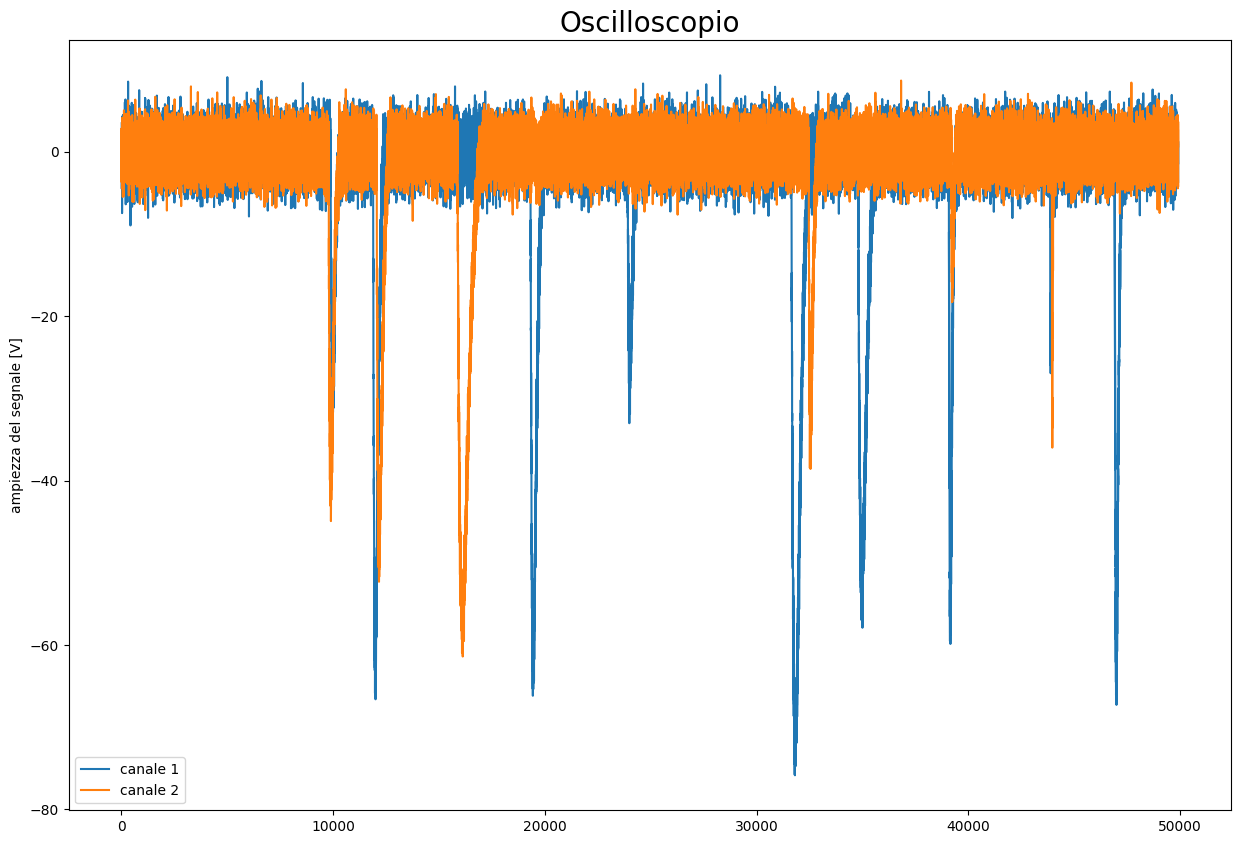

In [11]:
plt.figure(figsize=(15,10))
plt.plot(df['time'], df['signal1'], label='canale 1')
plt.plot(df['time'], df['signal2'], label='canale 2')
plt.ylabel('ampiezza del segnale [V]')
plt.title("Oscilloscopio", fontsize=20)
plt.legend()
plt.savefig("ocsilloscopio.png")
plt.show()


$$
f'(i) = \frac{ f(i+1) - f(i-1)}{ x(i+1) - x(i-1) }.
$$

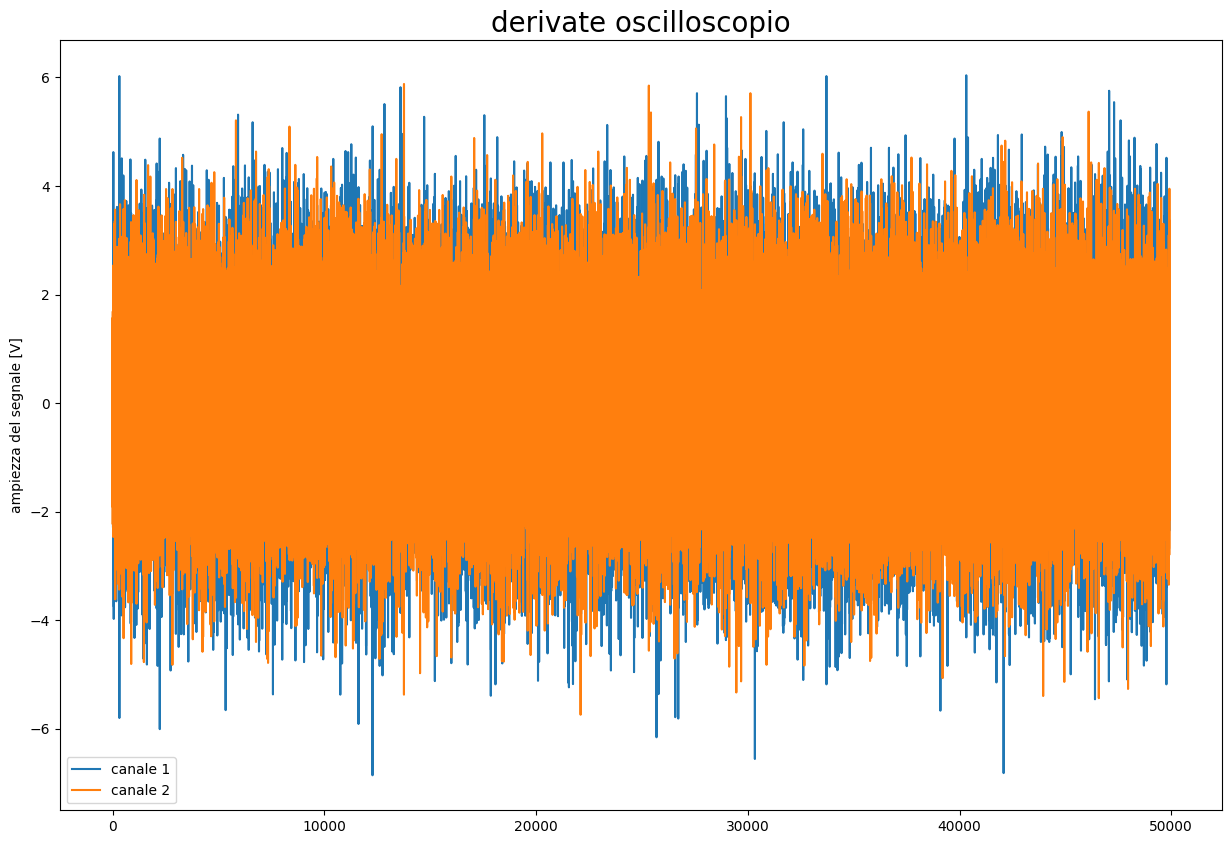

In [10]:
df['der_1']=df['der_2']=np.zeros(len(df['time']))
for i in range(1, len(df['time']) - 1):
  df.loc[i, 'der_1'] = (df['signal1'][i + 1] - df['signal1'][i - 1]) / (df['time'][i + 1] - df['time'][i - 1])
  df.loc[i, 'der_2'] = (df['signal2'][i + 1] - df['signal2'][i - 1]) / (df['time'][i + 1] - df['time'][i - 1])

plt.figure(figsize=(15,10))
plt.plot(df['time'], df['der_1'], label='canale 1')
plt.plot(df['time'], df['der_2'], label='canale 2')
plt.ylabel('ampiezza del segnale [V]')
plt.title("derivate oscilloscopio", fontsize=20)
plt.legend()
plt.savefig("ocsilloscopio.png")
plt.show()